# 07 — NLP: classifying tariff lines into CPI series

Decision D29. Each new counter-tariff list must be mapped to the consumer price index (D18). Done by hand, it took the longest part of step 3. Here, text methods rank the 123 food CPI series for each customs description, and are scored against the hand-made mapping (ground truth).

| Method | Idea, in one sentence |
|---|---|
| TF-IDF | Shared words and word fragments between the customs description and the CPI series name. |
| Embeddings | A multilingual language model turns each text into a vector; close meanings give close vectors, even without shared words. |
| Hybrid | Average of the two standardised scores (equal weights, fixed in advance). |
| RRF | Reciprocal Rank Fusion [N4]: each method votes 1 / (60 + rank); the standard rank-based fusion. |
| LLM (optional) | Claude picks one series among the 5 hybrid candidates, or "none", through a JSON schema that only allows those answers. |

Metrics: **top-1** (the first proposal is right), **recall@5** (the right series is among the 5 proposals a reviewer would see), **MRR**; *strict* (exact series) and *lenient* (the series or its direct parent/child).

In [1]:
import sys, os
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root / "src" / "nlp"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import hs_cpi_classifier as H
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

r = H.run()
gold, lab, cands = r["gold"], r["labelled"], r["candidates"]
print(f"{len(gold)} food HS6 subheadings on the 2018/2025/2026 lists; {len(lab)} have a gold CPI series; {len(cands)} candidate CPI series")
print("LLM step:", "run" if "llm" in r["results"] else "not run (no ANTHROPIC_API_KEY)")
gold.gold_exposure.replace("", "none").value_counts().rename("gold exposure")

151 food HS6 subheadings on the 2018/2025/2026 lists; 135 have a gold CPI series; 123 candidate CPI series
LLM step: not run (no ANTHROPIC_API_KEY)


gold_exposure
direct             103
none                16
partial             13
input               12
over_quota_only      7
Name: gold exposure, dtype: int64

## 1. Results

In [2]:
metrics = pd.DataFrame({k: m for k, (m, _) in r["results"].items()}).T
metrics.round(3)

,n,top1_strict,top1_lenient,recall@5_strict,recall@5_lenient,mrr_strict
tfidf,135.0,0.393,0.563,0.726,0.778,0.541
embeddings,135.0,0.356,0.659,0.719,0.956,0.508
hybrid,135.0,0.378,0.615,0.807,0.896,0.553
rrf,135.0,0.444,0.622,0.785,0.926,0.577


## 1b. Uncertainty and significance

135 lines is a small test set: 95% bootstrap intervals [N8] and exact McNemar tests [N9] on paired outcomes (same lines, two methods).

In [3]:
rows = []
golds = [set(x.split(";")) for x in lab.gold_set]
hits = {}
for name, (m, res) in r["results"].items():
    if name == "llm":
        continue
    t1 = (res.rank_strict == 1).to_numpy(); r5 = (res.rank_strict <= 5).to_numpy()
    hits[name] = (t1, r5)
    rows.append({"method": name, "top1_strict": t1.mean(), "top1_ci": "[{:.2f}; {:.2f}]".format(*H.bootstrap_ci(t1)),
                 "recall@5_strict": r5.mean(), "recall@5_ci": "[{:.2f}; {:.2f}]".format(*H.bootstrap_ci(r5))})
display(pd.DataFrame(rows).round(3))
tests = [{"comparison": f"{a} vs tfidf", "p_top1": H.mcnemar_exact(hits[a][0], hits["tfidf"][0]),
          "p_recall@5": H.mcnemar_exact(hits[a][1], hits["tfidf"][1])} for a in ["embeddings", "hybrid", "rrf"]]
pd.DataFrame(tests).round(3)

,method,top1_strict,top1_ci,recall@5_strict,recall@5_ci
0,tfidf,0.393,[0.31; 0.48],0.726,[0.65; 0.80]
1,embeddings,0.356,[0.27; 0.44],0.719,[0.64; 0.79]
2,hybrid,0.378,[0.30; 0.46],0.807,[0.74; 0.87]
3,rrf,0.444,[0.36; 0.53],0.785,[0.71; 0.85]


,comparison,p_top1,p_recall@5
0,embeddings vs tfidf,0.442,1.000
1,hybrid vs tfidf,0.774,0.007
2,rrf vs tfidf,0.118,0.115


## 2. Sensitivity of the hybrid weight

Shown for transparency only: picking the best weight on the same 135 lines would overstate performance, so the published hybrid keeps 50/50.

In [4]:
sens = []
for w in [0.0, 0.3, 0.5, 0.7, 1.0]:
    m, _ = H.evaluate(H.rank_hybrid(r["scores"]["tfidf"], r["scores"]["embeddings"], w), lab, cands)
    sens.append({"weight_tfidf": w, **{k: round(v, 3) for k, v in m.items() if k != "n"}})
pd.DataFrame(sens)

,weight_tfidf,top1_strict,top1_lenient,recall@5_strict,recall@5_lenient,mrr_strict
0,0.0,0.356,0.659,0.719,0.956,0.508
1,0.3,0.378,0.696,0.822,0.948,0.554
2,0.5,0.378,0.615,0.807,0.896,0.553
3,0.7,0.415,0.585,0.785,0.822,0.568
4,1.0,0.393,0.563,0.726,0.778,0.541


## 3. Recall by number of proposals shown to a reviewer

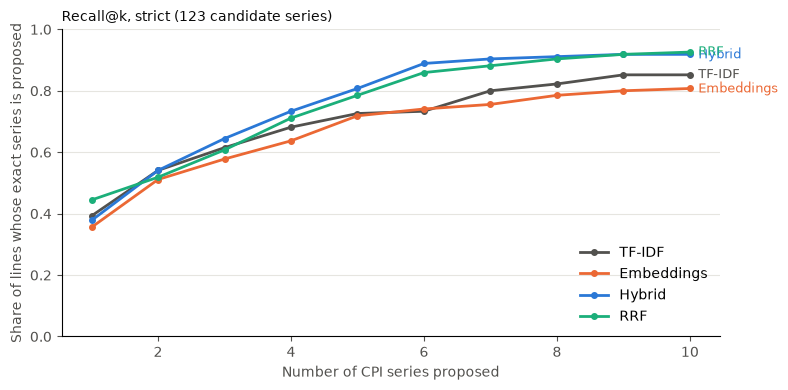

In [5]:
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e6e5e0"
ks = range(1, 11)
fig, ax = plt.subplots(figsize=(8, 4))
names = cands["product"].tolist()
for (name, sc), col in zip([("TF-IDF", r["scores"]["tfidf"]), ("Embeddings", r["scores"]["embeddings"]), ("Hybrid", r["scores"]["hybrid"]), ("RRF", r["scores"]["rrf"])], [MUTED, ORANGE, BLUE, AQUA]):
    order = np.argsort(-sc, axis=1)
    golds = [set(s.split(";")) for s in lab.gold_set]
    rec = [np.mean([any(names[j] in g for j in order[i, :k]) for i, g in enumerate(golds)]) for k in ks]
    ax.plot(list(ks), rec, color=col, lw=2, marker="o", ms=4, label=name)
    ax.annotate(name, (10, rec[-1]), xytext=(6, 0), textcoords="offset points", color=col, va="center", fontsize=9)
ax.set_xlabel("Number of CPI series proposed", color=MUTED); ax.set_ylabel("Share of lines whose exact series is proposed", color=MUTED)
ax.set_ylim(0, 1); ax.grid(axis="y", color=GRID); ax.tick_params(colors=MUTED)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Recall@k, strict (123 candidate series)", color=INK, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 4. Error analysis (hybrid, first proposal)

- **Level error**: right branch, wrong level (for example *Cheese* proposed for a line mapped to *Cheddar cheese*): a reviewer fixes it in one click.
- **Wrong branch**: a different product family.

In [6]:
res = r["results"]["hybrid"][1].merge(lab[["hs6", "description"]], on="hs6")
res["error"] = np.where(res.rank_strict == 1, "correct", np.where(res.rank_lenient == 1, "level error", "wrong branch"))
print(res.error.value_counts().to_string())
res[res.error == "wrong branch"][["hs6", "description", "gold", "top1"]].head(15)

error
wrong branch    52
correct         51
level error     32


,hs6,description,gold,top1
1,0207.12,"Meat and edible offal; of fowls of the species Gallus domesticus, ...",Fresh or frozen chicken,Other fresh or frozen poultry
2,0207.13,"Meat and edible offal; of fowls of the species Gallus domesticus, ...",Fresh or frozen chicken,Other fresh or frozen poultry
3,0207.14,"Meat and edible offal; of fowls of the species Gallus domesticus, ...",Fresh or frozen chicken,Other fresh or frozen poultry
8,0210.99,"Meat and edible meat offal; salted, in brine, dried or smoked, and...",Other processed meat,Fresh or frozen meat (excluding poultry)
13,0402.10,"Dairy produce; milk and cream, concentrated or containing added su...",Other dairy products,Low-fat milk (2013=100)
14,0402.21,"Dairy produce; milk and cream, concentrated, not containing added ...",Other dairy products,Low-fat milk (2013=100)
15,0402.91,"Dairy produce; milk and cream, concentrated, not containing added ...",Other dairy products,Fresh milk
16,0402.99,"Dairy produce; milk and cream, containing added sugar or other swe...",Other dairy products,Fresh milk
17,0403.10,"Dairy produce; yoghurt, whether or not concentrated or containing ...",Other dairy products,Fresh milk
18,0403.20,"Dairy produce; yoghurt, whether or not concentrated or containing ...",Other dairy products,Fresh milk


In [7]:
# The most frequent confusions
res[res.error != "correct"].groupby(["gold", "top1"]).size().sort_values(ascending=False).head(10).rename("lines")

gold                             top1                                     
Condiments, spices and vinegars  Herbs, spices and seasonings (2013=100)      17
Other edible fats and oils       Fresh vegetables                              7
Other dairy products             Fresh milk                                    6
Other processed meat             Fresh or frozen meat (excluding poultry)      4
Condiments, spices and vinegars  Nuts and seeds                                4
                                 Fresh fruit                                   4
Fresh milk                       Low-fat milk (2013=100)                       4
Confectionery                    Frozen food preparations                      3
Fresh or frozen chicken          Other fresh or frozen poultry                 3
Condiments, spices and vinegars  Berries (including cherries) (202304=100)     2
Name: lines, dtype: int64

In [8]:
out = root / "data/processed/nlp_hs_cpi_results.csv"
res.to_csv(out, index=False)
metrics.round(4).to_csv(root / "data/processed/nlp_hs_cpi_metrics.csv")
print("saved", out.relative_to(root))

saved data\processed\nlp_hs_cpi_results.csv


## 5. Findings

Written up in D29 (decision log).